# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


**Dataset yang digunakan: Telco Customer Churn (IBM)**

- **Sumber:** IBM sample data, juga tersedia di Kaggle (*blastchar/telco-customer-churn*).
- **Ukuran:** 7.043 baris, 21 kolom.
- **Tujuan:** memprediksi apakah seorang pelanggan akan berhenti berlangganan (`Churn` = Yes/No).
- **Jenis masalah:** klasifikasi biner pada data tabular terstruktur.

Kelompok fitur:
1. **Demografi:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`
2. **Layanan:** `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`
3. **Akun:** `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`
4. **Target:** `Churn`


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import os
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
RAW_PATH = "../telco_churn_raw/Telco-Customer-Churn.csv"
df = pd.read_csv(RAW_PATH)

print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

### 4.1 Pengecekan missing value dan duplikat

In [4]:
print("Missing value per kolom:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nJumlah baris duplikat (dengan customerID):", df.duplicated().sum())
print("Jumlah baris duplikat (tanpa customerID):", df.drop(columns="customerID").duplicated().sum())

Missing value per kolom:
Series([], dtype: int64)

Jumlah baris duplikat (dengan customerID): 0
Jumlah baris duplikat (tanpa customerID): 22


`isna()` tidak menemukan missing value, tetapi kolom `TotalCharges` bertipe teks (object), bukan angka. Itu tanda ada nilai yang bukan angka di dalamnya. Selain itu, setelah `customerID` diabaikan, ternyata ada baris yang isinya identik.

In [5]:
blank = df[df["TotalCharges"].str.strip() == ""]
print("Jumlah TotalCharges kosong:", len(blank))
blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Jumlah TotalCharges kosong: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Temuan:** 11 baris punya `TotalCharges` kosong, dan semuanya ber-`tenure` 0. Artinya mereka pelanggan baru yang belum pernah ditagih, sehingga nilai yang paling masuk akal adalah **0**, bukan dibuang atau diisi rata-rata.

### 4.2 Distribusi target

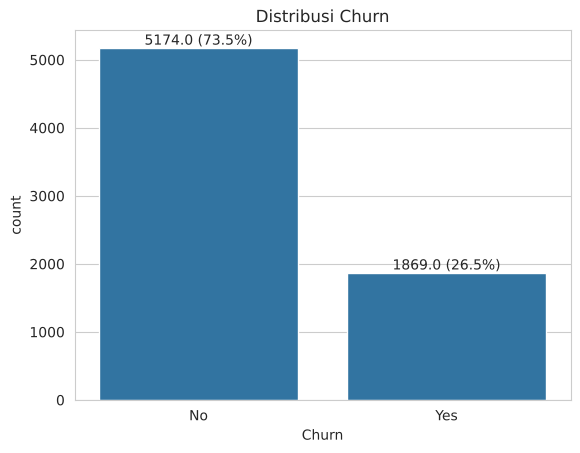

In [6]:
ax = sns.countplot(data=df, x="Churn")
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribusi Churn")
plt.show()

Target **tidak seimbang** (sekitar 73% tidak churn, 27% churn). Konsekuensinya: akurasi saja menyesatkan, karena model yang selalu menebak "No" sudah 73% akurat. Maka saat split data dipakai `stratify`, dan saat evaluasi model nanti perlu melihat precision, recall, dan F1.

### 4.3 Fitur numerik

In [7]:
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce").fillna(0)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df_eda[num_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


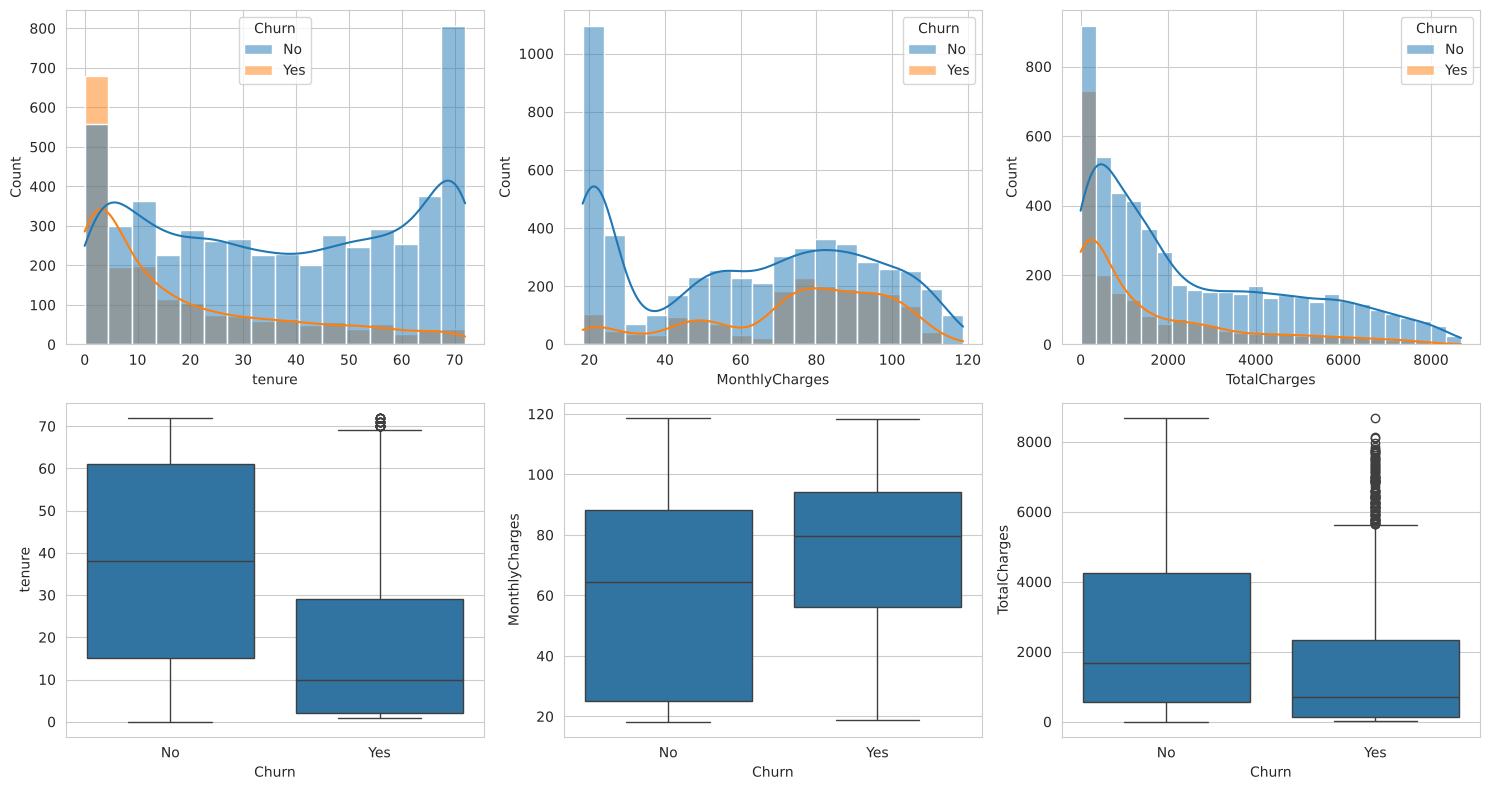

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    sns.histplot(data=df_eda, x=col, hue="Churn", kde=True, ax=axes[0, i])
    sns.boxplot(data=df_eda, x="Churn", y=col, ax=axes[1, i])
plt.tight_layout()
plt.show()

**Temuan:**
- Pelanggan yang churn cenderung punya `tenure` pendek (baru bergabung).
- Pelanggan yang churn cenderung punya `MonthlyCharges` lebih tinggi.
- Skala ketiga kolom sangat berbeda (puluhan vs ribuan), sehingga perlu standarisasi.

### 4.4 Fitur kategorikal terhadap churn

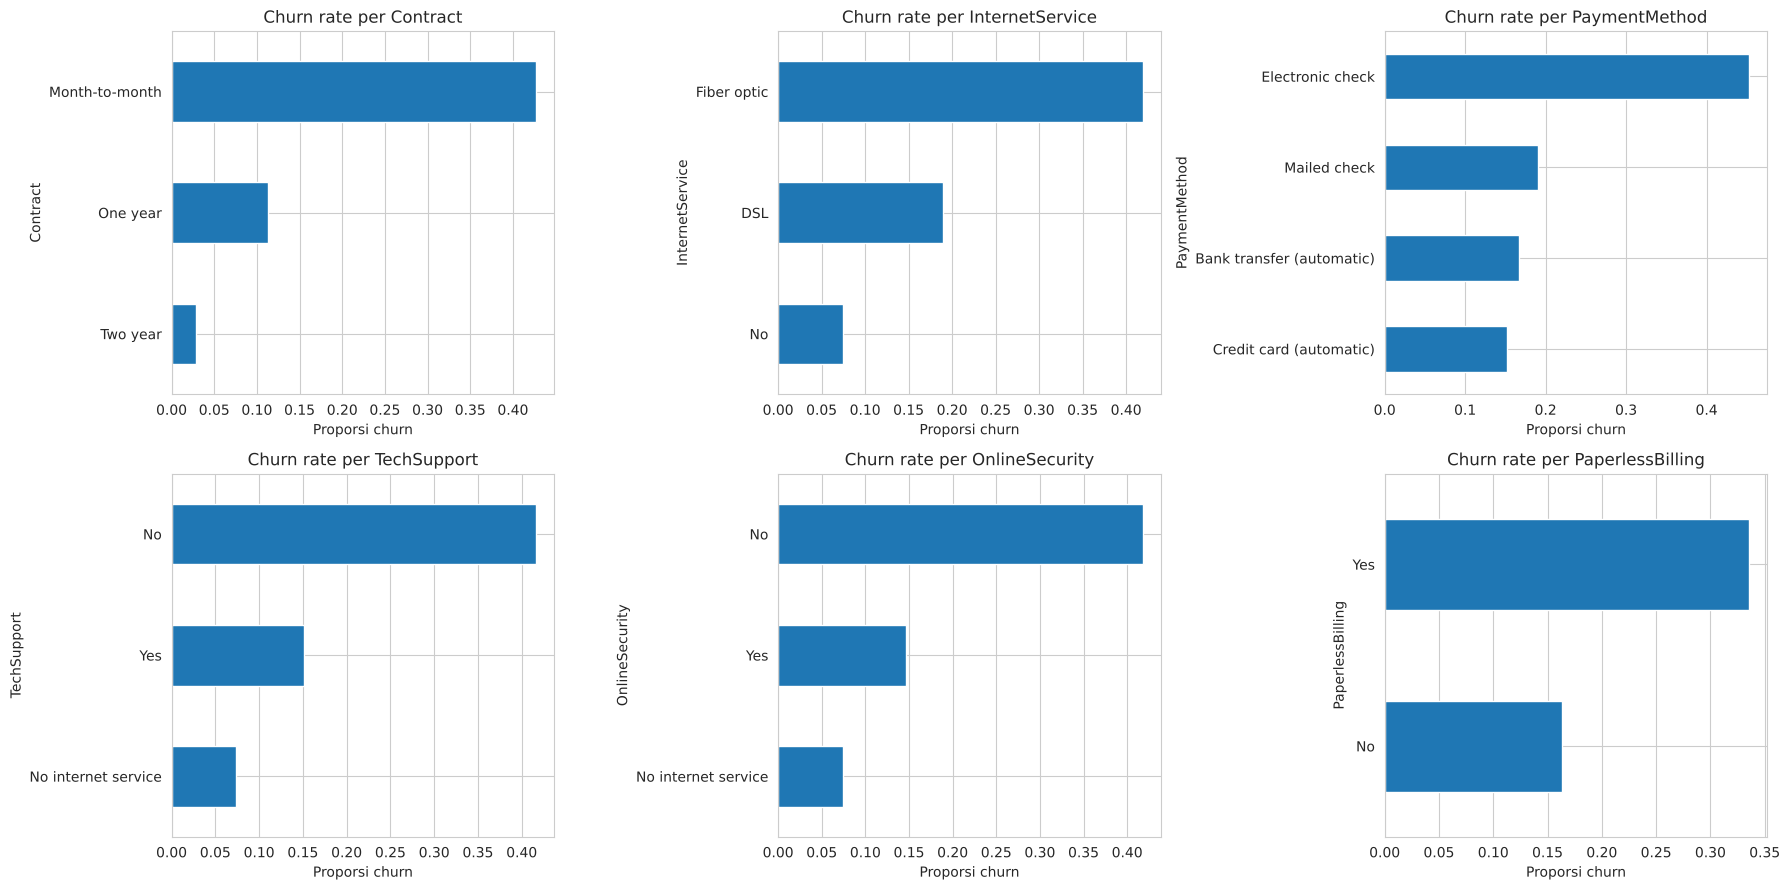

In [9]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values()
    rate.plot(kind="barh", ax=ax)
    ax.set_title(f"Churn rate per {col}")
    ax.set_xlabel("Proporsi churn")
plt.tight_layout()
plt.show()

**Temuan:** kontrak *Month-to-month*, internet *Fiber optic*, pembayaran *Electronic check*, serta tidak memakai *TechSupport* / *OnlineSecurity* berhubungan dengan churn rate yang jauh lebih tinggi. Fitur-fitur ini kemungkinan besar penting untuk model.

### 4.5 Korelasi fitur numerik

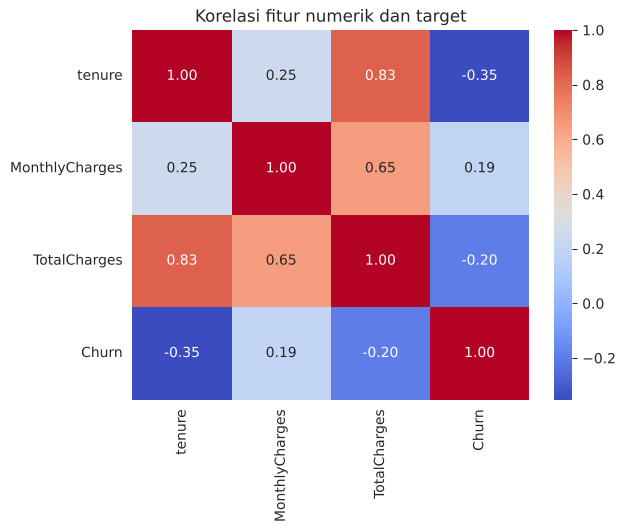

In [10]:
corr_df = df_eda[num_cols].copy()
corr_df["Churn"] = (df_eda["Churn"] == "Yes").astype(int)
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi fitur numerik dan target")
plt.show()

`TotalCharges` berkorelasi tinggi dengan `tenure` (wajar, karena total tagihan kira-kira tenure x tagihan bulanan). Untuk model berbasis pohon seperti Random Forest ini tidak bermasalah, jadi kolomnya tetap dipertahankan.

### 4.6 Pengecekan outlier (IQR)

In [11]:
for col in num_cols:
    q1, q3 = df_eda[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df_eda[col] < q1 - 1.5*iqr) | (df_eda[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n_out} outlier")

tenure: 0 outlier
MonthlyCharges: 0 outlier
TotalCharges: 0 outlier


Tidak ada outlier menurut aturan IQR. Langkah capping tetap dipasang di preprocessing sebagai pengaman jika data baru membawa nilai ekstrem.

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

### 5.1 Hapus kolom ID dan perbaiki tipe `TotalCharges`

In [12]:
df_clean = df.drop(columns=["customerID"])
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0)
print("Missing value tersisa:", df_clean.isna().sum().sum())

Missing value tersisa: 0


### 5.2 Hapus data duplikat

In [13]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Duplikat dihapus: {before - len(df_clean)} baris, sisa {len(df_clean)} baris")

Duplikat dihapus: 22 baris, sisa 7021 baris


### 5.3 Penanganan outlier (capping IQR)

In [14]:
for col in num_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_clean[col] = df_clean[col].clip(lower=q1 - 1.5*iqr, upper=q3 + 1.5*iqr)
df_clean[num_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7021.000000,7021.000000,7021.000000
mean,32.469449,64.851894,2286.765026
std,24.534965,30.069001,2266.855057
min,0.000000,18.250000,0.000000
25%,9.000000,35.750000,403.350000
50%,29.000000,70.400000,1400.550000
75%,55.000000,89.900000,3801.700000
max,72.000000,118.750000,8684.800000


### 5.4 Encoding data kategorikal

In [15]:
df_enc = df_clean.copy()
df_enc["Churn"] = df_enc["Churn"].map({"No": 0, "Yes": 1})
df_enc["gender"] = df_enc["gender"].map({"Female": 0, "Male": 1})
for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
    df_enc[col] = df_enc[col].map({"No": 0, "Yes": 1})

multi_cols = [c for c in df_enc.columns if df_enc[c].dtype == "object" or str(df_enc[c].dtype) == "str"]
print("Kolom one-hot:", multi_cols)
df_enc = pd.get_dummies(df_enc, columns=multi_cols, dtype=int)
print("Ukuran setelah encoding:", df_enc.shape)
df_enc.head()

Kolom one-hot: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Ukuran setelah encoding: (7021, 41)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0


### 5.5 Split data dan standarisasi

In [16]:
X = df_enc.drop(columns=["Churn"])
y = df_enc["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi churn train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (5616, 40) | Test: (1405, 40)
Proporsi churn train: 0.264 | test: 0.265


Scaler di-*fit* **hanya** pada data train, lalu dipakai untuk mentransformasi data test. Jika scaler di-fit pada seluruh data, informasi dari data test ikut bocor ke proses pelatihan (*data leakage*).

### 5.6 Simpan dataset hasil preprocessing

In [17]:
OUT_DIR = "telco_churn_preprocessing"
os.makedirs(OUT_DIR, exist_ok=True)
pd.concat([X_train, y_train], axis=1).to_csv(f"{OUT_DIR}/train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv(f"{OUT_DIR}/test.csv", index=False)
print("Tersimpan di", OUT_DIR, ":", os.listdir(OUT_DIR))

Tersimpan di telco_churn_preprocessing : ['train.csv', 'test.csv']
